## Aplicação estratégica: perguntas de negócio

### 0. Imports

In [1]:
import warnings
import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from google.cloud import bigquery
from pathlib import Path
from scipy.stats import rankdata
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, brier_score_loss, precision_score, r2_score, recall_score, roc_auc_score, root_mean_squared_error
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline

### 1. Parâmetros

In [2]:
par_entrada = Path("../data/processed")
par_source_project = "tech-challenge-fase-2-505123"
par_gold = f"{par_source_project}.gold"
par_alvo = "taxa_alfabetizacao"
par_grupo = "nome_mesorregiao"
par_rede_municipal = "3"
par_seed = 42
par_dobras = 5
par_bootstrap = 500
par_faixas_matriculas = [0, 200, 600, 2000, np.inf]
par_rotulos_matriculas = ["<200", "200-599", "600-1999", "2000+"]
par_limiar_taxa = 50
par_prob_alta = .7
par_prob_baixa = .3
par_min_avaliados = 30
par_ritmos = [3, 5]
par_lightgbm = {"colsample_bytree": 0.46769332346688064, "learning_rate": 0.015435211146627065, "min_child_samples": 48, "n_estimators": 515,
                "num_leaves": 7, "reg_lambda": 0.019104550307639058, "subsample": 0.6848272280307022, "subsample_freq": 1}  # melhor busca do notebook 3
par_cores = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
par_neutro = "#52514e"

client = bigquery.Client(project=par_source_project)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "axes.axisbelow": True,
                     "axes.titlelocation": "left", "axes.titlesize": 11, "font.size": 9})
pd.set_option("display.max_columns", 50, "display.max_rows", 80, "display.float_format", "{:,.3f}".format)

### 2. Funções Auxiliares

In [3]:
def sem_colunas(prep, remover, sem_indicadores=False):
    novo = clone(prep)
    novo.transformers = [(n, t, [c for c in cols if c not in remover]) for n, t, cols in novo.transformers
                         if not (sem_indicadores and n == "ausente")]
    return novo


def faixa_matriculas(df):
    return pd.cut(df["matriculas_anos_iniciais"], par_faixas_matriculas, labels=par_rotulos_matriculas, right=False).astype(str)


def residuos_oof(modelo, df, alvo=par_alvo):
    previsto = cross_val_predict(clone(modelo), df[par_features], df[alvo].astype(float), groups=df[par_grupo], cv=GroupKFold(n_splits=par_dobras))
    return previsto, df[alvo].astype(float).values - previsto


def prob_acima(previsto, limite, faixas, faixas_ref, residuos):
    distancia, faixas = np.asarray(limite, dtype=float) - np.asarray(previsto, dtype=float), np.asarray(faixas)
    prob = np.full(len(distancia), np.nan)
    for faixa in np.unique(faixas):
        mascara = faixas == faixa
        prob[mascara] = (residuos[np.asarray(faixas_ref) == faixa][:, None] >= distancia[mascara]).mean(axis=0)
    return prob


def bootstrap_grupos(grupos, funcao, repeticoes=par_bootstrap, seed=par_seed):
    rng = np.random.default_rng(seed)
    posicoes = pd.Series(np.arange(len(grupos))).groupby(np.asarray(grupos)).apply(lambda s: s.values)
    valores = []
    for _ in range(repeticoes):
        indices = np.concatenate(posicoes.values[rng.integers(0, len(posicoes), len(posicoes))])
        valores.append(funcao(indices))
    return np.percentile(valores, [2.5, 50, 97.5])


def eta2(df, grupo, valor):
    media = df[valor].astype(float).mean()
    entre = df.groupby(grupo, observed=True)[valor].agg(lambda s: len(s) * (s.astype(float).mean() - media) ** 2).sum()
    return entre / ((df[valor].astype(float) - media) ** 2).sum()


def variavel_original(nome):
    nome = nome.replace("ausente_", "")
    return next((c for c in par_categoricas if nome.startswith(c + "_")), nome)


def plot_barras(df, x, y, hue=None, titulo="", xlabel=None, referencia=None, fmt="%.2f", figsize=None):
    ordem = df[x].drop_duplicates().tolist()
    tab = df.pivot(index=x, columns=hue, values=y).reindex(ordem) if hue else df.set_index(x)[[y]]
    altura = max(2.4, .3 * len(tab) * (tab.shape[1] if hue else 1) + 1)
    ax = tab[::-1].plot.barh(figsize=figsize or (8, altura), color=par_cores[:tab.shape[1]], width=.8, edgecolor="white", linewidth=1.5, legend=bool(hue))
    if referencia is not None:
        ax.axvline(referencia, color=par_neutro, linestyle="--", linewidth=1)
    if not hue:
        ax.bar_label(ax.containers[0], fmt=fmt, padding=3, fontsize=8)
    ax.grid(axis="y", visible=False)
    ax.set(title=titulo, xlabel=xlabel or y, ylabel="")
    plt.tight_layout()
    plt.show()


def plot_mapa(ax, fundo, destaque, titulo, cor=par_cores[0]):
    ax.scatter(fundo["lon"], fundo["lat"], s=3, color="#dcdbd5", linewidths=0)
    ax.scatter(destaque["lon"], destaque["lat"], s=7, color=cor, linewidths=0)
    ax.set(title=titulo, xticks=[], yticks=[], aspect="equal")
    ax.grid(False)
    ax.spines[["left", "bottom"]].set_visible(False)

### 3. Leitura de dados

In [4]:
df_municipio = pd.read_parquet(par_entrada / "base_municipio.parquet")
df_escoragem = pd.read_parquet(par_entrada / "base_municipio_escoragem_2025.parquet")
df_catalogo = pd.read_csv(par_entrada / "catalogo_features.csv")
preprocessador = joblib.load(par_entrada / "preprocessador_municipio.joblib")
modelo_producao = joblib.load(par_entrada / "modelo_taxa_municipal.joblib")
par_features = df_catalogo.loc[df_catalogo["modelo_municipio"], "feature"].tolist()
par_familias = df_catalogo[df_catalogo["modelo_municipio"]].groupby("familia")["feature"].apply(list).to_dict()
par_categoricas = par_familias["territorio_categorico"]
par_territorio = par_familias["territorio_categorico"] + par_familias["territorio_numerico"]
df_municipio["faixa"] = faixa_matriculas(df_municipio)
df_escoragem["faixa"] = faixa_matriculas(df_escoragem)
df_ajuste = df_municipio[df_municipio["split"] != "teste"].copy()
df_teste = df_municipio[df_municipio["split"] == "teste"].copy()
print("2024:", df_municipio.shape, "| Ajuste:", df_ajuste.shape, "| Teste:", df_teste.shape, "| Escoragem 2025:", df_escoragem.shape)
print("Modelo:", modelo_producao.named_steps["modelo"])

2024: (5232, 48) | Ajuste: (4097, 48) | Teste: (1135, 48) | Escoragem 2025: (5352, 45)
Modelo: Lasso(alpha=np.float64(0.06672367170464207), max_iter=20000)


**Modelos usados**

In [5]:
modelo_lasso = clone(modelo_producao).fit(df_ajuste[par_features], df_ajuste[par_alvo].astype(float))
modelo_lgbm = Pipeline([("prep", clone(preprocessador)), ("modelo", lgb.LGBMRegressor(random_state=par_seed, n_jobs=1, verbose=-1, **par_lightgbm))])
modelo_lgbm.fit(df_ajuste[par_features], df_ajuste[par_alvo].astype(float))
modelo_sem_territorio = clone(modelo_producao).set_params(prep=sem_colunas(preprocessador, par_territorio, True))
pd.DataFrame([{"modelo": n, "rmse_teste": root_mean_squared_error(df_teste[par_alvo], m.predict(df_teste[par_features])), "r2_teste": r2_score(df_teste[par_alvo], m.predict(df_teste[par_features]))}
              for n, m in {"Lasso": modelo_lasso, "LightGBM": modelo_lgbm, "Lasso sem território": clone(modelo_sem_territorio).fit(df_ajuste[par_features], df_ajuste[par_alvo].astype(float))}.items()])

,modelo,rmse_teste,r2_teste
0,Lasso,11.269,0.710
1,LightGBM,11.378,0.704
2,Lasso sem território,12.337,0.652


### 4. Quais fatores mais impactam a alfabetização?

#### Quanto cada grupo de fatores explica

In [6]:
print("Variância da taxa entre regiões:", round(eta2(df_municipio, "nome_regiao", par_alvo), 3), "| entre UFs:", round(eta2(df_municipio, "sigla_uf", par_alvo), 3), "| entre mesorregiões:", round(eta2(df_municipio, par_grupo, par_alvo), 3))
par_rotulos_familia = {"historico": "Histórico", "socioeconomico": "Socioeconômico", "fluxo_escolar": "Fluxo escolar", "docentes_turmas": "Docentes e turmas",
                       "infraestrutura": "Infraestrutura", "financiamento": "Financiamento"}


def r2_familia(manter):
    remover = [c for c in par_features if c not in manter]
    pipe = clone(modelo_producao).set_params(prep=sem_colunas(preprocessador, remover, True))
    previsto = cross_val_predict(pipe, df_municipio[par_features], df_municipio[par_alvo].astype(float), groups=df_municipio[par_grupo], cv=GroupKFold(n_splits=par_dobras))
    return r2_score(df_municipio[par_alvo], previsto)


r2_territorio = r2_familia(par_territorio)
df_familias = pd.DataFrame([{"familia": rotulo, "r2_sozinha": r2_familia(par_familias[f]), "ganho_alem_do_territorio": r2_familia(par_familias[f] + par_territorio) - r2_territorio}
                            for f, rotulo in par_rotulos_familia.items()]).sort_values("r2_sozinha", ascending=False)
print("R² só com território:", round(r2_territorio, 3))
df_familias

Variância da taxa entre regiões: 0.131 | entre UFs: 0.485 | entre mesorregiões: 0.541


R² só com território: 0.445


,familia,r2_sozinha,ganho_alem_do_territorio
0,Histórico,0.482,0.182
2,Fluxo escolar,0.191,0.028
4,Infraestrutura,0.073,0.036
1,Socioeconômico,0.045,0.047
3,Docentes e turmas,0.036,0.009
5,Financiamento,0.011,0.006


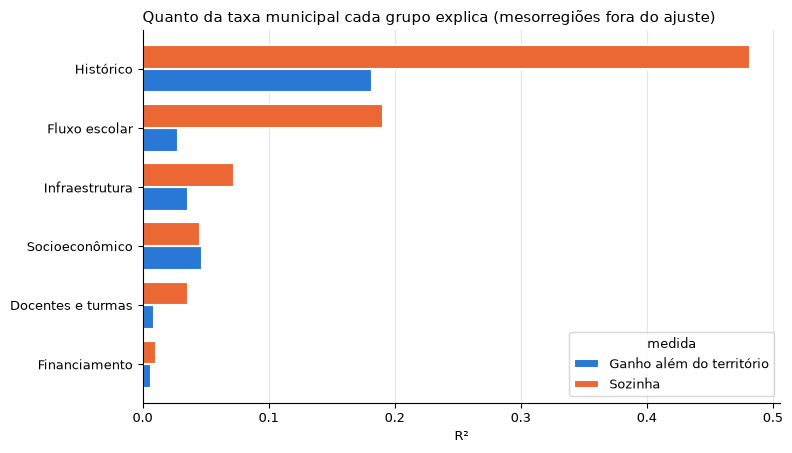

In [7]:
plot_barras(df_familias.melt("familia", var_name="medida", value_name="r2").replace({"r2_sozinha": "Sozinha", "ganho_alem_do_territorio": "Ganho além do território"}), "familia", "r2", hue="medida",
            titulo="Quanto da taxa municipal cada grupo explica (mesorregiões fora do ajuste)", xlabel="R²")

#### Fatores de contexto: associação com a taxa, dentro de cada UF

In [8]:
par_fatores = [f for fam in ["socioeconomico", "infraestrutura", "docentes_turmas", "fluxo_escolar", "financiamento"] for f in par_familias[fam]]
df_associacao = df_municipio[par_fatores + [par_alvo, "sigla_uf", par_grupo]].copy()
df_associacao[par_fatores + [par_alvo]] = df_associacao[par_fatores + [par_alvo]].astype(float)
df_dentro = df_associacao[par_fatores + [par_alvo]] - df_associacao.groupby("sigla_uf")[par_fatores + [par_alvo]].transform("mean")
linhas = []
for fator in par_fatores:
    valido = df_associacao[fator].notna().values
    x_bruto, x_dentro, y_bruto, y_dentro = [rankdata(v[valido]) for v in (df_associacao[fator].values, df_dentro[fator].values, df_associacao[par_alvo].values, df_dentro[par_alvo].values)]
    ic = bootstrap_grupos(df_associacao[par_grupo].values[valido], lambda i: np.corrcoef(x_dentro[i], y_dentro[i])[0, 1])
    quartil = df_associacao.loc[valido].groupby("sigla_uf")[fator].rank(pct=True)
    y_uf = df_dentro.loc[valido, par_alvo]
    linhas.append({"fator": fator, "familia": df_catalogo.set_index("feature").loc[fator, "familia"], "spearman_bruto": np.corrcoef(x_bruto, y_bruto)[0, 1], "spearman_uf": ic[1], "ic_min": ic[0], "ic_max": ic[2],
                   "dif_q4_q1_pontos": y_uf[quartil > .75].mean() - y_uf[quartil <= .25].mean()})
df_fatores = pd.DataFrame(linhas).sort_values("spearman_uf", key=np.abs, ascending=False).reset_index(drop=True)
df_fatores

,fator,familia,spearman_bruto,spearman_uf,ic_min,ic_max,dif_q4_q1_pontos
0,distorcao_idade_serie,fluxo_escolar,-0.387,-0.215,-0.247,-0.179,-8.599
1,escolas_anos_iniciais,infraestrutura,-0.286,-0.210,-0.253,-0.167,-8.466
2,taxa_abandono,fluxo_escolar,-0.418,-0.201,-0.231,-0.159,-10.450
3,matriculas_anos_iniciais,infraestrutura,-0.207,-0.201,-0.244,-0.156,-7.801
4,taxa_aprovacao,fluxo_escolar,0.418,0.197,0.163,0.228,7.240
5,populacao,socioeconomico,-0.191,-0.185,-0.235,-0.139,-7.644
6,invest_aluno_fundamental,financiamento,0.201,0.144,0.108,0.175,4.950
7,expectativa_anos_estudo,socioeconomico,0.229,0.141,0.103,0.178,4.366
8,alunos_por_turma,docentes_turmas,-0.127,-0.121,-0.158,-0.086,-4.407
9,indice_gini,socioeconomico,-0.211,-0.112,-0.147,-0.081,-3.597


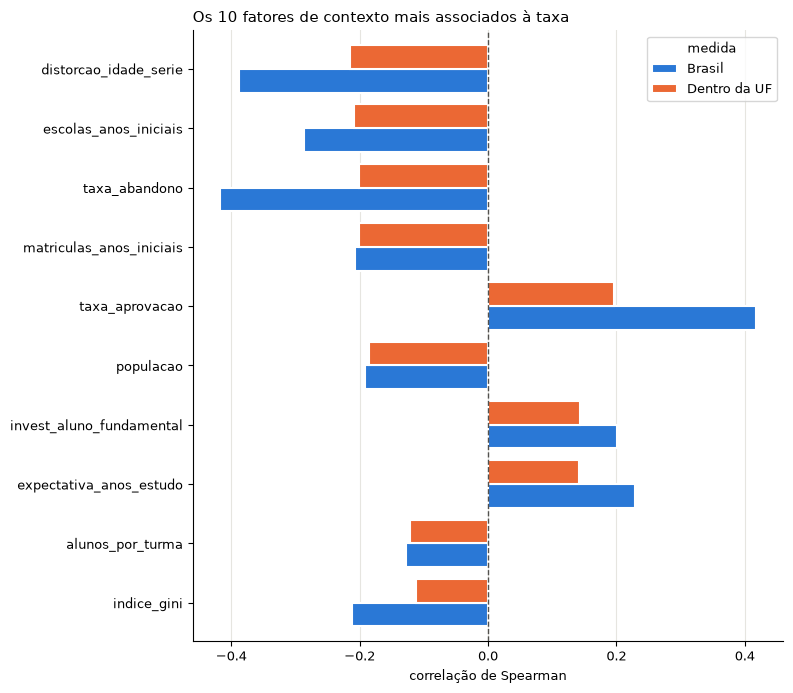

In [9]:
plot_barras(df_fatores.head(10).melt("fator", ["spearman_bruto", "spearman_uf"], var_name="medida", value_name="spearman").replace({"spearman_bruto": "Brasil", "spearman_uf": "Dentro da UF"}), "fator", "spearman", hue="medida",
            titulo="Os 10 fatores de contexto mais associados à taxa", xlabel="correlação de Spearman", referencia=0)

**Conclusão:** o fator mais forte é o histórico do próprio território, seguido do estado onde o município está. A UF concentra 48,5% da variância da taxa, contra 13,1% da região, e o território sozinho alcança R² de 0,445. Isso aponta para diferenças entre redes e políticas estaduais, mas os dados não permitem isolar a causa.

Entre os fatores de contexto, dentro da mesma UF:

| Fator | Spearman na UF | Quartil superior x inferior |
|---|---:|---:|
| Abandono escolar | -0,20 | -10,5 pontos |
| Distorção idade-série | -0,22 | -8,6 pontos |
| Aprovação | +0,20 | +7,2 pontos |
| População | -0,19 | -7,6 pontos |
| Investimento por aluno | +0,14 | +5,0 pontos |

- **Fluxo escolar:** é o grupo de contexto mais informativo (R² de 0,191 sozinho). Pode, porém, refletir o desempenho anterior, e não apenas causá-lo.
- **Porte:** municípios maiores têm taxas menores dentro da mesma UF.
- **Renda e IDHM:** quase não diferenciam municípios de uma mesma UF, com intervalos que incluem o zero. Esses dados são do Atlas de 2010, o que pode reduzir o sinal.
- **Além do território:** cada grupo de contexto acrescenta no máximo 0,047 de R²; só o histórico acrescenta mais (0,182).

São associações entre municípios, não efeitos causais nem características individuais das crianças.

### 5. Quais municípios apresentam maior risco educacional?

#### Por que há dois cenários: o efeito do RS

In [10]:
prep_producao = modelo_producao.named_steps["prep"]
par_nomes = [c.split("__")[1].replace("missingindicator_", "ausente_") for c in prep_producao.get_feature_names_out()]
df_coef = pd.Series(modelo_producao.named_steps["modelo"].coef_, index=par_nomes, name="coeficiente").sort_values(key=np.abs, ascending=False)
print(df_coef.head(5).round(2).to_string())
df_mudanca = df_municipio.assign(variacao=df_municipio[par_alvo] - df_municipio["taxa_lag"].astype(float))
print("\nVariação 2023-2024 no RS:", round(df_mudanca.query("sigla_uf == 'RS'")["variacao"].mean(), 1), "| demais UFs:", round(df_mudanca.query("sigla_uf != 'RS'")["variacao"].mean(), 1))
modelo_robusto = clone(modelo_sem_territorio).fit(df_municipio[par_features], df_municipio[par_alvo].astype(float))
df_risco = df_escoragem.copy()
df_risco["taxa_2024"] = df_risco["taxa_lag"].astype(float)
df_risco["prevista_producao"] = np.clip(modelo_producao.predict(df_risco[par_features]), 0, 100)
df_risco["prevista_robusta"] = np.clip(modelo_robusto.predict(df_risco[par_features]), 0, 100)
df_risco.assign(rs=np.where(df_risco["sigla_uf"] == "RS", "RS", "Demais UFs")).groupby("rs")[["taxa_2024", "prevista_producao", "prevista_robusta"]].mean()

sigla_uf_RS          -19.110
taxa_lag_suavizada     7.250
sigla_uf_MG            4.620
sigla_uf_BA           -4.530
nome_regiao_Sul       -4.330

Variação 2023-2024 no RS: -20.0 | demais UFs: 4.8


,taxa_2024,prevista_producao,prevista_robusta
rs,,,
Demais UFs,63.949,68.683,66.847
RS,52.937,39.209,59.517


**Decisão:** o risco é calculado com o Lasso sem território. O coeficiente do RS aprende a queda de 2024, que já está em `taxa_lag`; aplicá-lo de novo em 2025 supõe uma segunda queda igual. O modelo de produção segue como cenário de comparação.

#### Probabilidade de ficar abaixo de 50%

In [11]:
_, residuos_robusto = residuos_oof(modelo_sem_territorio, df_municipio)
df_risco["prob_abaixo_limiar"] = 1 - prob_acima(df_risco["prevista_robusta"], par_limiar_taxa, df_risco["faixa"], df_municipio["faixa"], residuos_robusto)
df_risco["nivel_risco"] = np.select([df_risco["prob_abaixo_limiar"] >= par_prob_alta, df_risco["prob_abaixo_limiar"] > par_prob_baixa], ["Alto", "Moderado"], "Baixo")
df_risco = df_risco.merge(df_municipio[["id_municipio", "taxa_lag"]].rename(columns={"taxa_lag": "taxa_2023"}), on="id_municipio", how="left")
df_risco["abaixo_dois_anos"] = (df_risco["taxa_2023"].astype(float) < par_limiar_taxa) & (df_risco["taxa_2024"] < par_limiar_taxa)
df_risco["criancas_nao_alfabetizadas"] = df_risco["n_avaliados_lag"].astype(float) * (100 - df_risco["prevista_robusta"]) / 100
df_risco["amostra_pequena"] = df_risco["n_avaliados_lag"].astype(float) < par_min_avaliados
df_risco["alto_producao"] = df_risco["prevista_producao"] < par_limiar_taxa
df_risco.groupby("nivel_risco").agg(municipios=("id_municipio", "size"), taxa_2024=("taxa_2024", "mean"), prevista=("prevista_robusta", "mean"), abaixo_dois_anos=("abaixo_dois_anos", "mean"),
                                    amostra_pequena=("amostra_pequena", "mean"), criancas=("criancas_nao_alfabetizadas", "sum")).reindex(["Alto", "Moderado", "Baixo"])

,municipios,taxa_2024,prevista,abaixo_dois_anos,amostra_pequena,criancas
nivel_risco,,,,,,
Alto,341,32.637,39.331,0.874,0.029,"90,425.558"
Moderado,831,44.404,50.862,0.513,0.162,"132,854.318"
Baixo,4180,69.227,71.497,0.052,0.107,"378,014.240"


#### Onde o risco se concentra

In [12]:
df_risco_uf = df_risco.groupby("sigla_uf").agg(municipios=("id_municipio", "size"), alto=("nivel_risco", lambda s: (s == "Alto").sum()), pct_alto=("nivel_risco", lambda s: 100 * (s == "Alto").mean()),
                                               taxa_2024=("taxa_2024", "mean"), criancas_alto=("criancas_nao_alfabetizadas", lambda s: s[df_risco.loc[s.index, "nivel_risco"] == "Alto"].sum())).sort_values("pct_alto", ascending=False)
df_risco_uf.head(12)

,municipios,alto,pct_alto,taxa_2024,criancas_alto
sigla_uf,,,,,
SE,75,39,52.000,36.447,"5,570.166"
BA,398,155,38.945,36.646,"32,281.958"
AM,55,18,32.727,45.005,"12,973.409"
RN,151,46,30.464,41.924,"5,183.825"
AC,22,6,27.273,43.500,669.195
PA,142,38,26.761,48.833,"12,173.723"
AP,16,2,12.500,49.449,354.171
RJ,92,10,10.870,58.736,"14,395.661"
TO,138,5,3.623,46.306,246.359


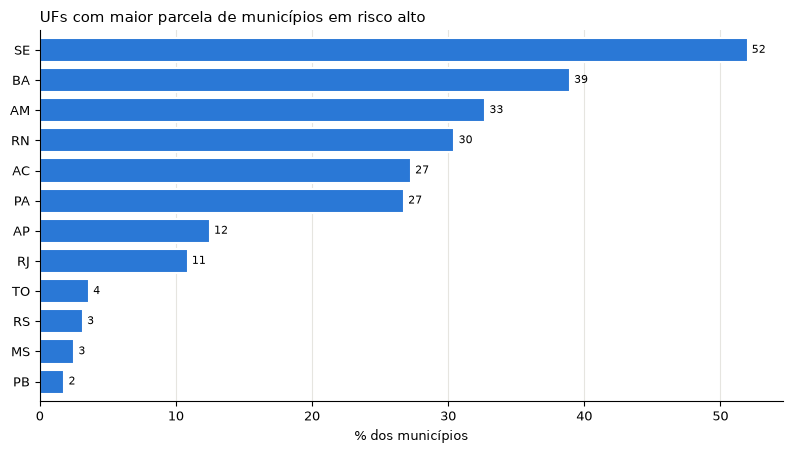

In [13]:
plot_barras(df_risco_uf.head(12).reset_index(), "sigla_uf", "pct_alto", titulo="UFs com maior parcela de municípios em risco alto", xlabel="% dos municípios", fmt="%.0f")

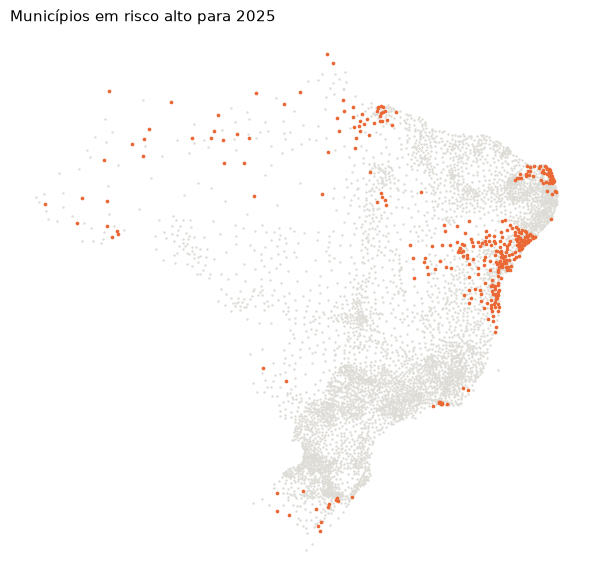

In [14]:
fig, ax = plt.subplots(figsize=(6, 6))
plot_mapa(ax, df_risco, df_risco[df_risco["nivel_risco"] == "Alto"], "Municípios em risco alto para 2025", par_cores[1])
plt.tight_layout()
plt.show()

#### Prioridade por taxa: os municípios mais críticos

In [15]:
par_colunas_risco = ["nome_municipio", "sigla_uf", "n_avaliados_lag", "taxa_2023", "taxa_2024", "prevista_robusta", "prob_abaixo_limiar", "criancas_nao_alfabetizadas"]
df_risco[(~df_risco["amostra_pequena"]) & df_risco["abaixo_dois_anos"]].sort_values(["prevista_robusta"]).head(15)[par_colunas_risco]

,nome_municipio,sigla_uf,n_avaliados_lag,taxa_2023,taxa_2024,prevista_robusta,prob_abaixo_limiar,criancas_nao_alfabetizadas
771,Itapebi,BA,64.000,14.970,23.440,23.599,0.992,48.897
904,Arataca,BA,61.000,16.860,13.110,24.208,0.992,46.233
2116,Rio do Fogo,RN,88.000,14.850,31.560,25.863,0.989,65.241
944,Pilão Arcado,BA,391.000,23.900,22.510,28.832,0.992,278.269
685,Itaju do Colônia,BA,59.000,20.170,15.250,29.264,0.928,41.734
835,Aporá,BA,230.000,17.780,16.520,30.186,0.971,160.573
2426,Curralinho,PA,510.000,25.060,24.030,30.555,0.989,354.168
848,Sátiro Dias,BA,88.000,15.360,30.680,30.607,0.969,61.066
637,Mascote,BA,101.000,22.320,26.730,30.648,0.969,70.045
2288,Uarini,AM,144.000,13.390,11.250,31.260,0.962,98.985


#### Prioridade por volume: onde há mais crianças afetadas

In [16]:
df_risco[df_risco["nivel_risco"] == "Alto"].sort_values("criancas_nao_alfabetizadas", ascending=False).head(15)[par_colunas_risco]

,nome_municipio,sigla_uf,n_avaliados_lag,taxa_2023,taxa_2024,prevista_robusta,prob_abaixo_limiar,criancas_nao_alfabetizadas
2256,Manaus,AM,"18,666.000",52.200,50.130,44.302,0.736,"10,396.553"
713,Salvador,BA,"12,112.000",39.160,36.750,41.463,0.834,"7,089.994"
3575,Nova Iguaçu,RJ,"6,380.000",33.230,33.420,40.944,0.858,"3,767.748"
3570,São Gonçalo,RJ,"4,415.000",45.670,43.710,41.579,0.826,"2,579.283"
670,Feira de Santana,BA,"3,528.000",31.960,33.190,32.487,0.985,"2,381.865"
3625,Campos dos Goytacazes,RJ,"3,890.000",38.690,38.330,43.674,0.757,"2,191.089"
3561,Belford Roxo,RJ,"3,174.000",34.730,38.900,38.146,0.916,"1,963.242"
3617,São João de Meriti,RJ,"2,543.000",37.600,35.970,42.635,0.788,"1,458.785"
2412,Castanhal,PA,"1,890.000",NaN,32.970,34.260,0.972,"1,242.493"
5093,Canoas,RS,"2,035.000",53.160,41.400,44.754,0.718,"1,124.260"


In [17]:
df_alto = df_risco[df_risco["nivel_risco"] == "Alto"].sort_values("criancas_nao_alfabetizadas", ascending=False)
print("Municípios em risco alto:", len(df_alto), "| 10% maiores concentram", round(100 * df_alto["criancas_nao_alfabetizadas"].head(len(df_alto) // 10).sum() / df_alto["criancas_nao_alfabetizadas"].sum(), 1), "% das crianças")
print("Risco alto com amostra < 30:", int(df_alto["amostra_pequena"].sum()), "| Abaixo de 50% nos dois anos:", int(df_alto["abaixo_dois_anos"].sum()), "| Sem taxa de 2023:", int(df_alto["taxa_2023"].isna().sum()))
print("RS em risco alto no cenário robusto:", int((df_alto["sigla_uf"] == "RS").sum()), "| RS abaixo de 50% no cenário de produção:", int(df_risco.query("sigla_uf == 'RS'")["alto_producao"].sum()), "de", (df_risco["sigla_uf"] == "RS").sum())

Municípios em risco alto: 341 | 10% maiores concentram 56.4 % das crianças
Risco alto com amostra < 30: 10 | Abaixo de 50% nos dois anos: 298 | Sem taxa de 2023: 27
RS em risco alto no cenário robusto: 14 | RS abaixo de 50% no cenário de produção: 425 de 441


**Conclusão:** 341 municípios (6,4%) têm risco alto, ou seja, probabilidade de pelo menos 70% de ficar abaixo de 50% em 2025. O limiar de 50% é uma escolha deste notebook. A taxa média desse grupo em 2024 foi de 32,6%, e 298 deles ficaram abaixo de 50% nos dois anos. A previsão soma cerca de 90 mil crianças avaliadas e não alfabetizadas nesse grupo.

- **Onde:** SE (52% dos municípios), BA (39%, ou 155 municípios), AM (33%), RN (30%), AC (27%) e PA (27%).
- **Menores taxas previstas:** Itapebi (BA), Arataca (BA), Rio do Fogo (RN) e Pilão Arcado (BA), entre 24% e 29%.
- **Mais crianças afetadas:** Manaus (cerca de 10,4 mil), Salvador (7,1 mil), Nova Iguaçu (3,8 mil), São Gonçalo (2,6 mil) e Feira de Santana (2,4 mil). Os 10% maiores municípios do grupo concentram 56% das crianças.

As duas listas pedem ações diferentes: apoio intensivo nos municípios com taxa crítica e escala nas grandes redes.

**Limites:** a escolha do cenário muda muito o RS, com 14 municípios em risco alto no cenário sem território, contra 425 de 441 previstos abaixo de 50% no modelo de produção. Como só há uma transição entre anos, não é possível saber qual cenário acertará em 2025. Dez municípios em risco alto têm menos de 30 alunos avaliados, e 27 não têm taxa de 2023; esses casos pedem confirmação antes de qualquer ação.

### 6. Como prever municípios que podem não atingir metas futuras?

**Método:** prever a taxa, subtrair a meta e converter a folga em probabilidade com os erros fora da amostra de cada faixa de porte.

#### Qualidade com mesorregiões novas (teste 2024)

In [18]:
y_meta = df_teste["atingiu_meta"].values
meta_teste = df_teste["meta_ano"].astype(float).values
modelo_robusto_ajuste = clone(modelo_sem_territorio).fit(df_ajuste[par_features], df_ajuste[par_alvo].astype(float))
classificador = clone(modelo_producao).set_params(modelo=LogisticRegression(C=.1, max_iter=5000)).fit(df_ajuste[par_features], df_ajuste["atingiu_meta"])
par_placares = {"Lasso: taxa - meta": modelo_lasso.predict(df_teste[par_features]) - meta_teste,
                "Lasso sem território: taxa - meta": modelo_robusto_ajuste.predict(df_teste[par_features]) - meta_teste,
                "Logística direta": classificador.predict_proba(df_teste[par_features])[:, 1] - .5,
                "Persistência: taxa 2023 - meta": df_teste["taxa_lag"].fillna(df_ajuste["taxa_lag"].median()).astype(float).values - meta_teste}
grupos_teste = df_teste[par_grupo].values
linhas = []
for nome, placar in par_placares.items():
    ic = bootstrap_grupos(grupos_teste, lambda i: roc_auc_score(y_meta[i], placar[i]))
    previsto = placar >= 0
    linhas.append({"abordagem": nome, "auc": roc_auc_score(y_meta, placar), "auc_min": ic[0], "auc_max": ic[2], "acuracia_balanceada": balanced_accuracy_score(y_meta, previsto),
                   "precisao_nao_atinge": precision_score(y_meta, previsto, pos_label=0), "recall_nao_atinge": recall_score(y_meta, previsto, pos_label=0)})
pd.DataFrame(linhas).sort_values("auc", ascending=False)

,abordagem,auc,auc_min,auc_max,acuracia_balanceada,precisao_nao_atinge,recall_nao_atinge
2,Logística direta,0.805,0.734,0.865,0.718,0.690,0.677
0,Lasso: taxa - meta,0.802,0.733,0.863,0.717,0.711,0.641
1,Lasso sem território: taxa - meta,0.763,0.701,0.823,0.697,0.646,0.697
3,Persistência: taxa 2023 - meta,0.575,0.453,0.695,0.553,0.478,0.791


#### Teste mais próximo do uso real: treinar em 2023 e prever 2024

In [19]:
df_2023 = (pd.read_parquet(par_entrada / "base_aluno.parquet", filters=[("ano_alvo", "==", 2023), ("rede_id", "==", par_rede_municipal)])
           .drop_duplicates("id_municipio").drop(columns=["alfabetizado", "peso_amostral", "id_escola", "alunos_previstos_escola"]))
df_taxa_2023 = client.query(f"""select id_municipio, taxa_alfabetizacao from `{par_gold}.fato_indicador_municipio` where ano = 2023 and rede_id = "{par_rede_municipal}" """).to_dataframe()
df_2023 = df_2023.merge(df_taxa_2023, on="id_municipio")
df_2023[["meta_ano", "esforco_meta"]] = np.nan
df_2023["faixa"] = faixa_matriculas(df_2023)
par_sem_tempo = par_familias["historico"] + par_familias["metas"]
modelo_temporal = clone(modelo_producao).set_params(prep=sem_colunas(preprocessador, par_sem_tempo, True))
_, residuos_2023 = residuos_oof(modelo_temporal, df_2023)
modelo_temporal.fit(df_2023[par_features], df_2023[par_alvo].astype(float))
previsto_temporal = modelo_temporal.predict(df_municipio[par_features])
meta_2024 = df_municipio["meta_ano"].astype(float).values
y_temporal = df_municipio["atingiu_meta"].values
print("Municípios de treino (2023):", len(df_2023), "| Previstos (2024):", len(df_municipio))
print("AUC temporal:", round(roc_auc_score(y_temporal, previsto_temporal - meta_2024), 3), "| Acurácia balanceada:", round(balanced_accuracy_score(y_temporal, previsto_temporal >= meta_2024), 3))
df_uf_temporal = df_municipio.assign(placar=previsto_temporal - meta_2024).groupby("sigla_uf").filter(lambda d: d["atingiu_meta"].nunique() == 2 and len(d) >= 50)
print("AUC temporal média dentro da UF:", round(df_uf_temporal.groupby("sigla_uf").apply(lambda d: roc_auc_score(d["atingiu_meta"], d["placar"])).mean(), 3))
mascara_rs = (df_municipio["sigla_uf"] == "RS").values
print("Metas atingidas no RS, previsto x real (%):", round(100 * (previsto_temporal >= meta_2024)[mascara_rs].mean(), 1), "x", round(100 * y_temporal[mascara_rs].mean(), 1))

Municípios de treino (2023): 4821 | Previstos (2024): 5232
AUC temporal: 0.646 | Acurácia balanceada: 0.61
AUC temporal média dentro da UF: 0.634
Metas atingidas no RS, previsto x real (%): 37.8 x 9.5


#### As probabilidades são confiáveis?

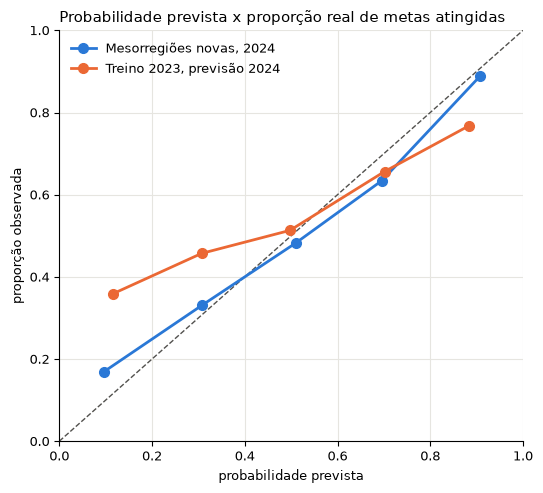

,cenario,brier,brier_referencia,previsto_pct,real_pct
0,"Mesorregiões novas, 2024",0.179,0.247,56.659,55.771
1,"Treino 2023, previsão 2024",0.250,0.249,47.361,53.287


In [20]:
_, residuos_ajuste = residuos_oof(modelo_producao, df_ajuste)
prob_teste = prob_acima(modelo_lasso.predict(df_teste[par_features]), meta_teste, df_teste["faixa"], df_ajuste["faixa"], residuos_ajuste)
prob_temporal = prob_acima(previsto_temporal, meta_2024, df_municipio["faixa"], df_2023["faixa"], residuos_2023)
par_faixas_prob = np.linspace(0, 1, 6)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], color=par_neutro, linestyle="--", linewidth=1)
linhas = []
for i, (nome, prob, real) in enumerate([("Mesorregiões novas, 2024", prob_teste, y_meta), ("Treino 2023, previsão 2024", prob_temporal, y_temporal)]):
    tab = pd.DataFrame({"prob": prob, "real": real}).groupby(pd.cut(prob, par_faixas_prob, include_lowest=True), observed=True).agg(previsto=("prob", "mean"), observado=("real", "mean"), n=("real", "size"))
    ax.plot(tab["previsto"], tab["observado"], marker="o", markersize=7, linewidth=2, color=par_cores[i], label=nome)
    linhas.append({"cenario": nome, "brier": brier_score_loss(real, prob), "brier_referencia": brier_score_loss(real, np.full(len(real), real.mean())), "previsto_pct": 100 * prob.mean(), "real_pct": 100 * real.mean()})
ax.set(title="Probabilidade prevista x proporção real de metas atingidas", xlabel="probabilidade prevista", ylabel="proporção observada", xlim=(0, 1), ylim=(0, 1))
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
pd.DataFrame(linhas)

#### Meta de 2025: dois cenários

In [21]:
_, residuos_producao = residuos_oof(modelo_producao, df_municipio)
df_metas = df_risco[["id_municipio", "nome_municipio", "sigla_uf", "nome_regiao", "faixa", "n_avaliados_lag", "taxa_2024", "meta_ano", "prevista_producao", "prevista_robusta"]].copy()
df_metas["meta_ano"] = df_metas["meta_ano"].astype(float)
df_metas["prob_meta_producao"] = prob_acima(df_metas["prevista_producao"], df_metas["meta_ano"], df_metas["faixa"], df_municipio["faixa"], residuos_producao)
df_metas["prob_meta_robusta"] = prob_acima(df_metas["prevista_robusta"], df_metas["meta_ano"], df_metas["faixa"], df_municipio["faixa"], residuos_robusto)
for coluna in ["producao", "robusta"]:
    df_metas[f"alerta_{coluna}"] = np.select([df_metas[f"prob_meta_{coluna}"] <= par_prob_baixa, df_metas[f"prob_meta_{coluna}"] >= par_prob_alta], ["Provável não atingir", "Provável atingir"], "Incerto")
df_metas["alerta_consenso"] = np.where(df_metas["alerta_producao"] == df_metas["alerta_robusta"], df_metas["alerta_robusta"], "Incerto")
pd.DataFrame({c: df_metas[f"alerta_{c}"].value_counts() for c in ["producao", "robusta", "consenso"]}).reindex(["Provável não atingir", "Incerto", "Provável atingir"])

,producao,robusta,consenso
Provável não atingir,1459,1093,972
Incerto,1726,2718,2952
Provável atingir,2167,1541,1428


In [22]:
df_metas_uf = df_metas.groupby("sigla_uf").agg(municipios=("id_municipio", "size"), taxa_2024=("taxa_2024", "mean"), meta=("meta_ano", "mean"), producao=("prob_meta_producao", lambda s: 100 * s.mean()), robusta=("prob_meta_robusta", lambda s: 100 * s.mean()),
                                               nao_atingir_consenso=("alerta_consenso", lambda s: 100 * (s == "Provável não atingir").mean())).sort_values("robusta")
df_metas_uf["diferenca"] = df_metas_uf["producao"] - df_metas_uf["robusta"]
print("% esperado de municípios que atingem: produção", round(df_metas["prob_meta_producao"].mean() * 100, 1), "| robusto", round(df_metas["prob_meta_robusta"].mean() * 100, 1))
df_metas_uf

% esperado de municípios que atingem: produção 54.7 | robusto 53.1


,municipios,taxa_2024,meta,producao,robusta,nao_atingir_consenso,diferenca
sigla_uf,,,,,,,
RS,441,52.937,72.786,2.355,20.336,76.417,-17.981
RJ,92,58.736,63.505,32.456,22.108,56.522,10.348
PA,142,48.833,56.629,24.031,26.638,55.634,-2.607
AM,55,45.005,55.991,21.202,28.641,60.000,-7.439
BA,398,36.646,50.218,16.697,36.783,42.714,-20.086
SC,254,69.092,70.670,44.988,39.602,18.504,5.387
PR,398,74.039,75.473,42.657,41.712,14.573,0.946
AC,22,43.500,49.912,35.535,45.868,27.273,-10.332
RO,52,67.182,69.357,56.017,46.904,15.385,9.113


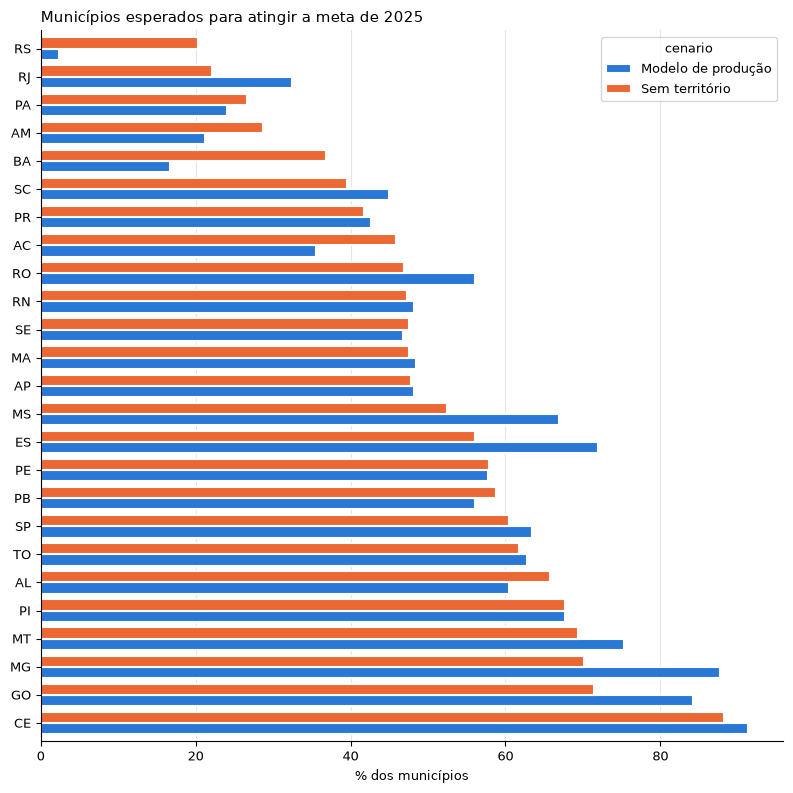

In [23]:
plot_barras(df_metas_uf.reset_index().melt("sigla_uf", ["producao", "robusta"], var_name="cenario", value_name="pct").replace({"producao": "Modelo de produção", "robusta": "Sem território"}), "sigla_uf", "pct", hue="cenario",
            titulo="Municípios esperados para atingir a meta de 2025", xlabel="% dos municípios", figsize=(8, 8))

In [24]:
df_alerta = df_metas[df_metas["alerta_consenso"] == "Provável não atingir"]
print("Em alerta:", len(df_alerta), "| Já acima da meta de 2025 em 2024:", int((df_alerta["taxa_2024"] >= df_alerta["meta_ano"]).sum()), "| Amostra < 30:", int((df_alerta["n_avaliados_lag"].astype(float) < par_min_avaliados).sum()))
df_alerta[(df_alerta["taxa_2024"] < df_alerta["meta_ano"]) & (df_alerta["n_avaliados_lag"].astype(float) >= par_min_avaliados)].assign(falta_2024=lambda d: d["meta_ano"] - d["taxa_2024"]).sort_values("n_avaliados_lag", ascending=False).head(15)[["nome_municipio", "sigla_uf", "n_avaliados_lag", "taxa_2024", "meta_ano", "prevista_robusta", "prevista_producao", "prob_meta_robusta", "prob_meta_producao"]]

Em alerta: 972 | Já acima da meta de 2025 em 2024: 58 | Amostra < 30: 121


,nome_municipio,sigla_uf,n_avaliados_lag,taxa_2024,meta_ano,prevista_robusta,prevista_producao,prob_meta_robusta,prob_meta_producao
3609,Rio de Janeiro,RJ,"43,340.000",63.750,63.970,53.730,57.787,0.113,0.176
2256,Manaus,AM,"18,666.000",50.130,61.280,44.302,43.693,0.016,0.012
4610,Curitiba,PR,"12,923.000",65.960,73.410,61.730,63.752,0.086,0.078
713,Salvador,BA,"12,112.000",36.750,52.030,41.463,33.951,0.107,0.012
1735,Recife,PE,"9,859.000",54.360,68.080,62.678,60.155,0.272,0.120
3859,São Bernardo do Campo,SP,"6,727.000",54.160,63.550,57.577,58.733,0.254,0.233
3572,Duque de Caxias,RJ,"6,581.000",45.370,57.800,46.902,45.831,0.099,0.049
3575,Nova Iguaçu,RJ,"6,380.000",33.420,47.440,40.944,39.840,0.237,0.129
544,Maceió,AL,"5,283.000",40.950,52.090,46.075,45.472,0.254,0.158
2475,Porto Velho,RO,"5,154.000",50.840,69.850,61.826,60.050,0.189,0.075


#### Até 2030: ritmo necessário

In [25]:
df_meta_2030 = client.query(f"""
select local_id as id_municipio, max_by(valor_meta, ano_referencia) as meta_2030
from `{par_gold}.fato_meta`
where nivel_geografico = "municipio" and ano_meta = 2030
group by 1
""").to_dataframe()
df_ritmo = df_risco[["id_municipio", "nome_regiao", "sigla_uf", "taxa_2023", "taxa_2024"]].merge(df_meta_2030, on="id_municipio")
df_ritmo["meta_2030"] = df_ritmo["meta_2030"].astype(float)
df_ritmo["ritmo_exigido"] = (df_ritmo["meta_2030"] - df_ritmo["taxa_2024"]) / 6
variacao = (df_ritmo["taxa_2024"] - df_ritmo["taxa_2023"].astype(float)).dropna()
print("Com meta de 2030:", len(df_ritmo), "de", len(df_risco), "| Já na meta:", round(100 * (df_ritmo["ritmo_exigido"] <= 0).mean(), 1), "%")
print("Precisam de mais de 3 pontos/ano:", round(100 * (df_ritmo["ritmo_exigido"] > 3).mean(), 1), "% | mais de 5:", round(100 * (df_ritmo["ritmo_exigido"] > 5).mean(), 1), "%")
print("Variação 2023-2024: média", round(variacao.mean(), 2), "| mediana", round(variacao.median(), 2), "| fora do RS", round((df_ritmo["taxa_2024"] - df_ritmo["taxa_2023"].astype(float))[df_ritmo["sigla_uf"] != "RS"].mean(), 2))
df_ritmo.groupby("nome_regiao").agg(municipios=("id_municipio", "size"), taxa_2024=("taxa_2024", "mean"), meta_2030=("meta_2030", "mean"), ritmo_medio=("ritmo_exigido", "mean"),
                                    **{f"pct_acima_{r}": ("ritmo_exigido", lambda s, r=r: 100 * (s > r).mean()) for r in par_ritmos})

Com meta de 2030: 5352 de 5352 | Já na meta: 21.3 %
Precisam de mais de 3 pontos/ano: 46.4 % | mais de 5: 26.8 %
Variação 2023-2024: média 2.78 | mediana 2.62 | fora do RS 4.78


,municipios,taxa_2024,meta_2030,ritmo_medio,pct_acima_3,pct_acima_5
nome_regiao,,,,,,
Centro-Oeste,464,72.344,80.000,1.276,26.078,7.759
Nordeste,1756,56.571,80.000,3.905,62.699,45.216
Norte,425,49.509,80.000,5.082,79.059,52.941
Sudeste,1614,70.068,80.000,1.655,29.182,9.294
Sul,1093,64.375,80.000,2.604,41.446,20.860


**Conclusão:** a abordagem recomendada é prever a taxa, compará-la com a meta e converter a folga em probabilidade. Ela empata com a classificação direta (AUC de 0,802 contra 0,805, esta sem busca de hiperparâmetros) e também informa a distância até a meta. Repetir a taxa do ano anterior não basta (AUC de 0,575).

O desempenho para anos futuros deve ser menor que o de 0,80:

| Teste | AUC | O que mede |
|---|---:|---|
| Mesorregiões novas, com UF | 0,802 | Otimista: a UF já contém o choque do mesmo ano |
| Mesorregiões novas, sem território | 0,763 | Sem esse efeito de UF, mas com coeficientes do mesmo ano |
| Treino em 2023, previsão de 2024 | 0,646 | Pessimista: não há histórico em 2023 |

No teste temporal, as probabilidades não superam a referência (Brier de 0,250 contra 0,249), e o modelo não antecipou a queda do RS (37,8% previstos, 9,5% reais). A expectativa razoável fica entre 0,65 e 0,76, com as probabilidades servindo para ordenar municípios, não como valores exatos.

**Meta de 2025:** cerca de 53% a 55% dos municípios devem atingi-la, mas com diferenças grandes por UF (RS de 2% a 20%, BA de 17% a 37%, MG de 70% a 88%). Os dois cenários concordam em 972 municípios com provável não atingimento e 1.428 com provável atingimento; os outros 2.952 ficam como incertos. Rio de Janeiro, Manaus, Curitiba e Salvador estão entre os maiores municípios em alerta.

**Antes de usar a lista:** 58 municípios em alerta já superaram a meta de 2025 em 2024, e 121 têm menos de 30 avaliados. Em algumas grandes cidades, a previsão recua bastante em relação a 2024: o Rio de Janeiro vai de 63,8% para 53,7%, com meta de 64,0%. Esses casos precisam de revisão.

**Até 2030:** o modelo não projeta tão longe, pois há apenas uma transição entre anos. O ritmo exigido é um alerta complementar: 46,4% dos municípios precisam de mais de 3 pontos por ano e 26,8% de mais de 5, chegando a 79,1% e 52,9% no Norte. A variação observada em 2023-2024 foi de 2,8 pontos em média (4,8 fora do RS), em um único ano e com muito ruído. Com os resultados de 2025, o modelo deve ser reavaliado com uma segunda transição.

### 7. Quais variáveis possuem maior influência nos modelos?

**Método:** comparar o Lasso (escolhido) e o LightGBM (melhor na partição de validação) nas mesorregiões de teste, usando SHAP e permutação. One-hot e indicadores de ausência são somados à variável original.

#### SHAP por variável

In [26]:
def shap_por_variavel(modelo, tipo):
    prep = modelo.named_steps["prep"]
    nomes = [c.split("__")[1].replace("missingindicator_", "ausente_") for c in prep.get_feature_names_out()]
    X_prep = pd.DataFrame(prep.transform(df_teste[par_features]), columns=nomes).astype(float)
    if tipo == "linear":
        valores = shap.Explainer(modelo.named_steps["modelo"], shap.maskers.Independent(X_prep.sample(min(300, len(X_prep)), random_state=par_seed), max_samples=300))(X_prep).values
    else:
        valores = shap.TreeExplainer(modelo.named_steps["modelo"]).shap_values(X_prep)
    return pd.DataFrame(valores, columns=nomes).T.groupby(variavel_original).sum().T.abs().mean()


df_shap = pd.DataFrame({"Lasso": shap_por_variavel(modelo_lasso, "linear"), "LightGBM": shap_por_variavel(modelo_lgbm, "arvore")})
df_shap["familia"] = df_catalogo.set_index("feature")["familia"].reindex(df_shap.index)
print("Correlação de postos entre modelos:", round(df_shap["Lasso"].corr(df_shap["LightGBM"], method="spearman"), 3))
df_shap = df_shap.sort_values("Lasso", ascending=False)
df_shap.head(15)

Correlação de postos entre modelos: 0.528


,Lasso,LightGBM,familia
taxa_lag_suavizada,6.607,3.432,historico
sigla_uf,2.786,1.454,territorio_categorico
taxa_lag_vizinhos,2.751,2.193,historico
taxa_lag_uf,2.271,2.380,historico
nome_regiao,1.754,0.203,territorio_categorico
media_portugues_lag,1.487,2.761,historico
taxa_presenca_lag,1.434,1.320,historico
populacao,0.988,0.391,socioeconomico
renda_pc,0.890,0.174,socioeconomico
taxa_aprovacao,0.795,0.591,fluxo_escolar


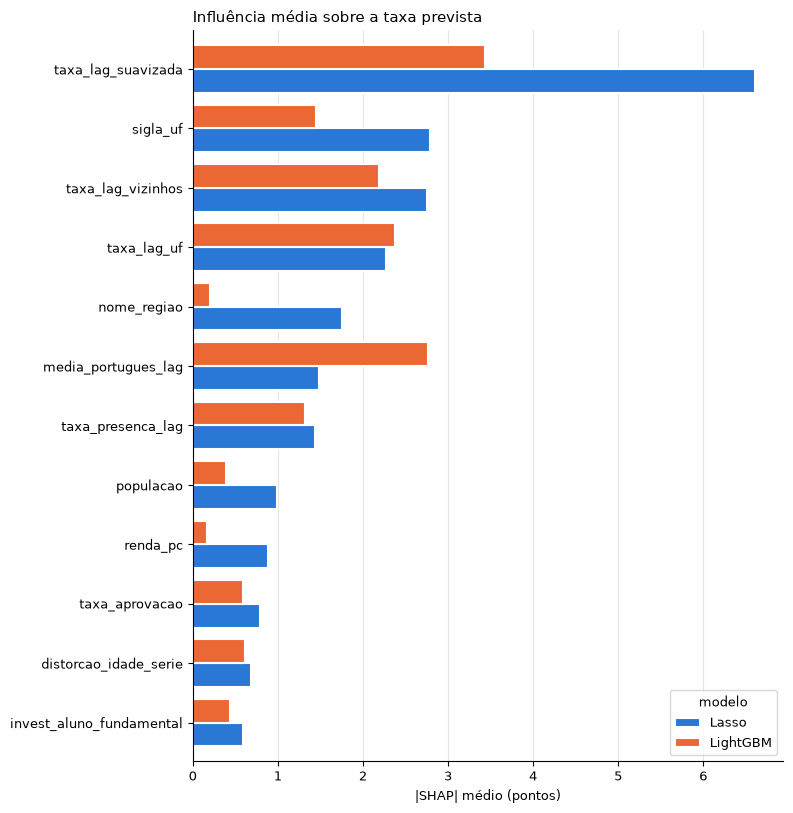

In [27]:
plot_barras(df_shap.head(12).reset_index(names="variavel").melt("variavel", ["Lasso", "LightGBM"], var_name="modelo", value_name="shap"), "variavel", "shap", hue="modelo",
            titulo="Influência média sobre a taxa prevista", xlabel="|SHAP| médio (pontos)")

#### Permutação por família: efeito no erro de teste

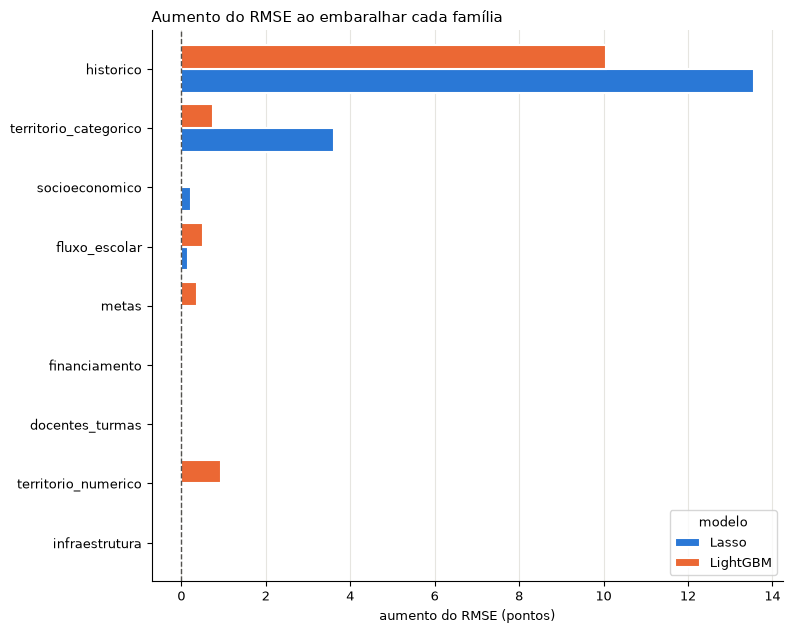

mean            std         
modelo                 Lasso LightGBM Lasso LightGBM
familia                                             
historico             13.571   10.056 0.234    0.172
territorio_categorico  3.625    0.744 0.169    0.089
socioeconomico         0.233    0.025 0.040    0.032
fluxo_escolar          0.150    0.508 0.059    0.060
metas                  0.025    0.361 0.021    0.044
financiamento          0.020    0.016 0.022    0.015
docentes_turmas        0.000    0.005 0.004    0.014
territorio_numerico   -0.000    0.946 0.000    0.068
infraestrutura        -0.025   -0.002 0.011    0.021

In [28]:
def permutar_familias(modelo, repeticoes=20):
    rng = np.random.default_rng(par_seed)
    base = root_mean_squared_error(df_teste[par_alvo], modelo.predict(df_teste[par_features]))
    linhas = []
    for familia, colunas in par_familias.items():
        for _ in range(repeticoes):
            permutado = df_teste[par_features].copy()
            permutado[colunas] = permutado[colunas].iloc[rng.permutation(len(permutado))].values
            linhas.append({"familia": familia, "aumento": root_mean_squared_error(df_teste[par_alvo], modelo.predict(permutado)) - base})
    return pd.DataFrame(linhas).groupby("familia")["aumento"].agg(["mean", "std"])


df_perm = pd.concat({"Lasso": permutar_familias(modelo_lasso), "LightGBM": permutar_familias(modelo_lgbm)}, names=["modelo"]).reset_index().sort_values(["modelo", "mean"], ascending=[True, False])
ordem_perm = df_perm[df_perm["modelo"] == "Lasso"]["familia"].tolist()
df_perm_ordem = df_perm.set_index("familia").loc[ordem_perm].reset_index()
plot_barras(df_perm_ordem, "familia", "mean", hue="modelo", titulo="Aumento do RMSE ao embaralhar cada família", xlabel="aumento do RMSE (pontos)", referencia=0)
df_perm_ordem.pivot(index="familia", columns="modelo", values=["mean", "std"]).reindex(ordem_perm)

#### Estabilidade do Lasso entre dobras

In [29]:
linhas = []
for dobra, (treino, _) in enumerate(GroupKFold(n_splits=par_dobras).split(df_ajuste, groups=df_ajuste[par_grupo])):
    ajustado = clone(modelo_producao).fit(df_ajuste.iloc[treino][par_features], df_ajuste.iloc[treino][par_alvo].astype(float))
    nomes = [c.split("__")[1].replace("missingindicator_", "ausente_") for c in ajustado.named_steps["prep"].get_feature_names_out()]
    linhas.append(pd.Series(ajustado.named_steps["modelo"].coef_, index=nomes, name=dobra))
df_dobras = pd.concat(linhas, axis=1).fillna(0)
df_estabilidade = pd.DataFrame({"dobras_com_efeito": (df_dobras != 0).sum(axis=1), "coef_medio": df_dobras.mean(axis=1), "coef_min": df_dobras.min(axis=1), "coef_max": df_dobras.max(axis=1)})
print("Termos sempre selecionados:", (df_estabilidade["dobras_com_efeito"] == par_dobras).sum(), "de", len(df_estabilidade), "| Nunca selecionados:", (df_estabilidade["dobras_com_efeito"] == 0).sum())
df_estabilidade.sort_values("coef_medio", key=np.abs, ascending=False).head(15)

Termos sempre selecionados: 22 de 83 | Nunca selecionados: 39


,dobras_com_efeito,coef_medio,coef_min,coef_max
sigla_uf_RS,5,-19.542,-20.088,-18.772
taxa_lag_suavizada,5,6.444,5.770,7.018
nome_regiao_Sul,5,-4.759,-5.304,-4.083
sigla_uf_MG,5,4.183,3.812,4.937
ausente_taxa_presenca_lag,5,-3.687,-4.453,-2.727
sigla_uf_BA,5,-3.388,-3.894,-2.376
taxa_lag_vizinhos,5,2.767,2.426,2.862
taxa_lag_uf,5,2.566,2.152,2.870
sigla_uf_SP,5,-1.705,-2.133,-1.144
media_portugues_lag,5,1.496,0.971,1.949


#### Modelo de aluno: a mesma hierarquia?

As importâncias do LightGBM de aluno vêm de `src.evaluation.avaliar_aluno`, calculadas nas mesorregiões de teste com um ajuste que não usa o teste. Para comparar escalas diferentes (AUC e RMSE), cada família é expressa como parte do efeito total do modelo.

In [30]:
par_avaliacao_aluno = par_entrada.parent.parent / "reports" / "avaliacao" / "aluno"
df_familia_aluno = pd.read_csv(par_avaliacao_aluno / "importancia_familia.csv").rename(columns={"nome": "familia"}).set_index("familia")
df_shap_aluno = pd.read_csv(par_avaliacao_aluno / "importancia_shap.csv")
df_comparacao = pd.DataFrame({"aluno_queda_auc": df_familia_aluno["queda_auc"],
                              "lasso_aumento_rmse": df_perm[df_perm["modelo"] == "Lasso"].set_index("familia")["mean"]})
for coluna in ["aluno_queda_auc", "lasso_aumento_rmse"]:
    df_comparacao[coluna.split("_")[0] + "_pct"] = 100 * df_comparacao[coluna].clip(lower=0) / df_comparacao[coluna].clip(lower=0).sum()
print("Principais variáveis no SHAP do aluno:", ", ".join(df_shap_aluno["variavel"].head(6)))
df_comparacao.sort_values("aluno_queda_auc", ascending=False)

Principais variáveis no SHAP do aluno: taxa_lag_suavizada, media_portugues_lag, taxa_presenca_lag, taxa_lag, taxa_lag_uf, taxa_lag_vizinhos


,aluno_queda_auc,lasso_aumento_rmse,aluno_pct,lasso_pct
familia,,,,
historico,0.193,13.571,96.772,76.999
territorio_categorico,0.003,3.625,1.587,20.568
fluxo_escolar,0.001,0.150,0.459,0.852
socioeconomico,0.001,0.233,0.429,1.321
territorio_numerico,0.001,-0.000,0.397,0.000
escola,0.000,NaN,0.238,NaN
docentes_turmas,0.000,0.000,0.057,0.002
financiamento,0.000,0.020,0.041,0.114
rede,0.000,NaN,0.020,NaN


**Conclusão:** as variáveis mais influentes são as de histórico, seguidas das territoriais. Embaralhar o histórico aumenta o RMSE em 13,6 pontos no Lasso e 10,1 no LightGBM, muito acima de qualquer outra família.

- **Comum aos dois modelos:** `taxa_lag_suavizada`, `taxa_lag_vizinhos`, `taxa_lag_uf`, `media_portugues_lag` e `taxa_presenca_lag` estão entre as principais.
- **Diferença entre modelos:** a correlação de postos é moderada (0,53). O território entra de formas distintas: no Lasso, UF e região somam +3,6 pontos de RMSE, enquanto o LightGBM divide esse sinal entre latitude e longitude (+0,9) e UF e região (+0,7). Variáveis individuais correlacionadas podem trocar de posição, então o resultado por família é mais confiável.
- **Contexto:** fluxo escolar, população, renda e investimento têm efeito pequeno e consistente nos SHAP, mas pouco alteram o erro depois de considerado o histórico. No Lasso, docentes e infraestrutura não alteram o erro.
- **Estabilidade:** 22 dos 83 termos do Lasso aparecem nas 5 dobras e 39 nunca aparecem. O maior coeficiente, `sigla_uf_RS` (cerca de -19,5 pontos), é estável, mas descreve o choque de 2024, não um fator estrutural.
- **Modelo de aluno:** segue a mesma hierarquia, ainda mais concentrada. O histórico responde por 97% do efeito de permutação no LightGBM de aluno, contra 77% no Lasso, e o território categórico (UF, região, capital e Amazônia Legal) por 1,6%, contra 21%. Sem variáveis individuais, o modelo de aluno aprende sobretudo o nível do território e não capta as diferenças dentro da escola.

**Influência no modelo não equivale a impacto na alfabetização:** o histórico prevê bem, mas não é uma alavanca de política. Para decidir onde agir, a referência é a seção 4; o peso de histórico e UF indica que o modelo serve mais para antecipar onde o risco está do que para explicar por quê.

### 8. Salvar artefatos

In [31]:
df_risco.merge(df_metas[["id_municipio", "prob_meta_producao", "prob_meta_robusta", "alerta_consenso"]], on="id_municipio")[
    ["id_municipio", "nome_municipio", "sigla_uf", "nome_regiao", "n_avaliados_lag", "taxa_2023", "taxa_2024", "meta_ano", "prevista_producao", "prevista_robusta", "prob_abaixo_limiar", "nivel_risco", "abaixo_dois_anos",
     "amostra_pequena", "criancas_nao_alfabetizadas", "prob_meta_producao", "prob_meta_robusta", "alerta_consenso"]].to_csv(par_entrada / "risco_municipios_2025.csv", index=False)